In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("train.csv")

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.shape

(891, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 2. Data Cleaning

### 2.1 Checking Duplicate Records

We check whether the dataset contains any duplicate passenger records.

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['Age'].median()

28.0

In [10]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [11]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [12]:
df = df.drop(columns=['Cabin'])

In [13]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Total missing values: 0


In [14]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (891, 11)
Missing values: 0
Duplicate rows: 0


## 3. Data Analysis

### 3.1 Survival Analysis by Gender

We analyze the survival rate of male and female passengers to identify which gender had a higher chance of survival.

In [15]:
gender_survival = df.groupby('Sex')['Survived'].mean() * 100

print(gender_survival)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


**Observation:**

The survival rate of female passengers was approximately 74.20%, whereas the survival rate of male passengers was approximately 18.89%. Therefore, female passengers had a significantly higher survival rate than male passengers in the Titanic dataset.

### 3.2 Survival Analysis by Passenger Class

We analyze the survival rate across different passenger classes to understand how passenger class was associated with survival chances.

In [16]:
class_survival = df.groupby('Pclass')['Survived'].mean() * 100

print(class_survival)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


Observation

Passengers in first class had a higher survival rate (62.96%) compared to second class (47.28%) and third class (24.24%). This indicates that passenger class was associated with survival chances. First-class passengers were more likely to survive than passengers in lower classes.

### 3.3 Survival Analysis by Age Group

In [21]:
bins = [0, 12, 18, 35, 60, 100]

labels = ['Child (0-12)', 'Teenager (13-18)', 'Adult (19-35)',
          'Middle-aged (36-60)', 'Senior (61+)']

df['AgeGroup'] = pd.cut(df['Age'], bins=bins, labels=labels, include_lowest=True)

age_survival = df.groupby('AgeGroup', observed=True)['Survived'].mean() * 100

print(age_survival)

AgeGroup
Child (0-12)           57.971014
Teenager (13-18)       42.857143
Adult (19-35)          35.327103
Middle-aged (36-60)    40.000000
Senior (61+)           22.727273
Name: Survived, dtype: float64


**Observation:**
Children had the highest survival rate (57.97%), followed by middle-aged passengers (40%). Senior passengers had the lowest survival rate (22.73%). This indicates that age was associated with survival chances.

## 4. Data Visualization
### 4.1 Survival Rate by Gender

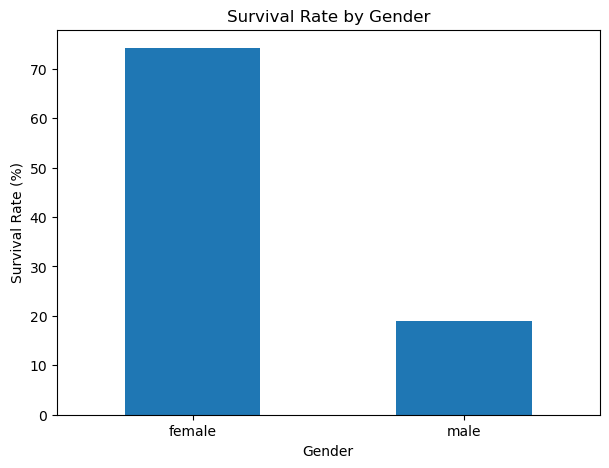

In [22]:
plt.figure(figsize=(7, 5))
gender_survival.plot(kind='bar')

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.show()

**Observation:**
Female passengers had a much higher survival rate (74.20%) compared to male passengers (18.89%). This indicates that female passengers were more likely to survive.

### 4.2 Survival Rate by Passenger Class

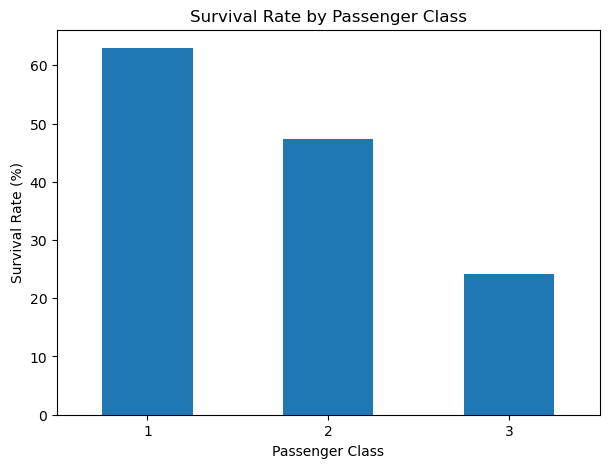

In [23]:
plt.figure(figsize=(7, 5))
class_survival.plot(kind='bar')

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.show()

**Observation:**
First-class passengers had the highest survival rate (62.96%), followed by second-class passengers (47.28%). Third-class passengers had the lowest survival rate (24.24%).

### 4.3 Distribution of Passenger Ages

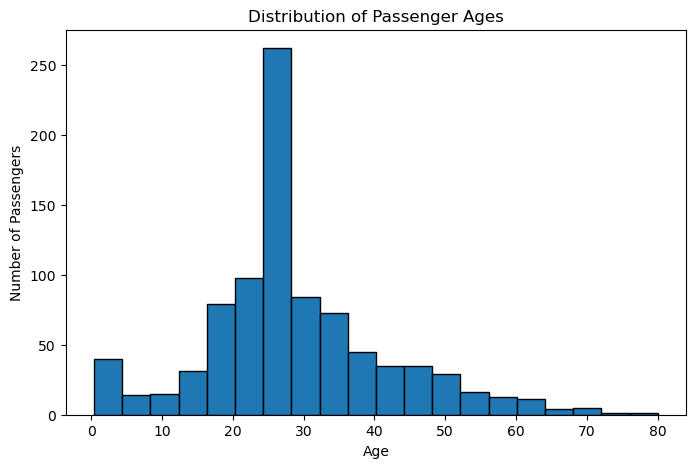

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age'], bins=20, edgecolor='black')

plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.show()

**Observation:**
Most passengers were between 20 and 30 years old. The number of passengers gradually decreased at older ages. Only a small number of passengers were above 60 years old.

## 5. Conclusion

The Titanic Survival Analysis revealed that gender, passenger class, and age were associated with survival chances.

- Female passengers had a higher survival rate than male passengers.
- First-class passengers had the highest survival rate, while third-class passengers had the lowest.
- Children had the highest survival rate among the age groups, while senior passengers had the lowest.
- Most passengers were between 20 and 30 years old.

This analysis helped identify important patterns in passenger survival using data cleaning, analysis, and visualization.